# Chapitre 11 - Exercices 11.1 à 11.5

Ce notebook traite les cinq premiers exercices du chapitre 11, centrés sur une
machine, le stockage distribué et le modèle MapReduce :

- **11.1** : table de hachage ou tri ? Ordres de grandeur d'une analyse de journal
  trop grosse pour la mémoire (calcul) ;
- **11.2** : régler la fusion d'un tri externe, entre nombre de passes et accès
  disque (calcul et mini-lab) ;
- **11.3** : dimensionner un système de fichiers distribué : métadonnées, réplication
  ou codes d'effacement, trafic de réparation (calcul) ;
- **11.4** : préemption et taille des tâches : trouver la granularité optimale (calcul
  et simulation) ;
- **11.5** : le combineur, et pourquoi il ne marche pas pour une moyenne (mini-lab).

In [1]:
import math
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 11.1 : table de hachage ou tri ?

**Énoncé.** Un site produit chaque jour 2 To de journaux d'accès (lignes de 250 octets en
moyenne). On veut compter les requêtes par couple (adresse IP, URL). Une étude préalable
estime à 1,5 milliard le nombre de couples distincts. On dispose d'une machine de 64 Go
de RAM, avec un disque qui lit et écrit séquentiellement à 500 Mo/s.

1. Combien de lignes le journal contient-il ? Quelle mémoire faudrait-il à une table de
   hachage (on compte 100 octets par entrée, clé et compteur compris, dans un langage
   compilé) ? Tient-elle en mémoire ?
2. On procède comme le pipeline Unix : on extrait les clés (60 octets par clé en
   moyenne), on les trie par tri externe avec 50 Go de tampon et une fusion à 10 voies,
   puis on compte les répétitions au fil de la fusion finale. Combien de segments, de
   passes de fusion ? Quel volume lit-on et écrit-on, et combien de temps cela prend-il
   au minimum ?
3. Même question si l'on compte seulement par URL (200 000 URL distinctes).
4. Pourquoi le tri externe reste-t-il possible quelle que soit la taille des données,
   alors que la table de hachage échoue brutalement ?

**Rappels.** Ensemble de travail d'une agrégation par hachage, tri externe (segments
triés puis fusion à $k$ voies, $\lceil \log_k(N/M) \rceil$ passes) : cours 1, section 4
(section *Sorting Versus In-Memory Aggregation*).

**Solution.**

*1.* $2 \cdot 10^{12} / 250 = 8 \cdot 10^9$ lignes. Table de hachage : $1{,}5 \cdot 10^9
\times 100 = 150$ Go, plus du double de la RAM. Elle ne tient pas : le système se met à
paginer (accès aléatoires sur disque, des millions de fois plus lents) puis manque de
mémoire.

*2.* Clés extraites : $8 \cdot 10^9 \times 60 = 480$ Go. Segments : $480/50 = 10$. Avec
une fusion à 10 voies, **une seule** passe de fusion suffit, et elle peut alimenter
directement le comptage. Volumes : lecture du journal (2 To), écriture des segments
(480 Go), relecture des segments (480 Go), soit 2,96 To de transferts séquentiels :
$2{,}96 \cdot 10^{12} / 5 \cdot 10^8 \approx 5\,900$ s, environ **1 h 40** (si le
processeur suit). La lecture initiale représente les deux tiers du temps.

*3.* Par URL : $200\,000 \times 100$ octets = 20 Mo. La table tient largement : une seule
lecture du journal, environ 4 000 s, limitée par le disque. Le tri n'apporte rien.

*4.* Le tri externe n'a besoin en mémoire que d'un paquet à trier et d'un tampon par
segment fusionné ; si les données grossissent, il ajoute des segments, puis des passes,
et son coût croît en $N \log(N/M)$. La table de hachage a besoin d'une entrée par clé
distincte **en accès aléatoire** : au-delà de la RAM, rien ne va plus.

In [2]:
lignes = 2e12 / 250
cles = 8e9 * 60
segments = math.ceil(cles / 50e9)
passes = B.merge_passes(segments, 10)
octets = 2e12 + cles * (1 + passes)          # lecture du journal + écriture des segments + relecture à chaque passe
pd.DataFrame({"valeur": [fmt(lignes), f"{1.5e9 * 100 / 1e9:.0f} Go", f"{cles / 1e9:.0f} Go", segments, passes,
                         f"{octets / 1e12:.2f} To", f"{octets / 5e8 / 3600:.2f} h", f"{2e12 / 5e8 / 3600:.2f} h"]},
             index=["lignes", "table de hachage (IP, URL)", "clés extraites", "segments", "passes de fusion",
                    "volume transféré", "durée minimale (tri)", "durée minimale (hachage par URL)"])

,valeur
lignes,8 000 000 000
"table de hachage (IP, URL)",150 Go
clés extraites,480 Go
segments,10
passes de fusion,1
volume transféré,2.96 To
durée minimale (tri),1.64 h
durée minimale (hachage par URL),1.11 h


**Vérification expérimentale** à échelle réduite : trions $N$ clés avec une mémoire de
$M$ éléments et une fusion à 10 voies, pour des rapports $N/M$ croissants, et comparons
les passes mesurées à la formule.

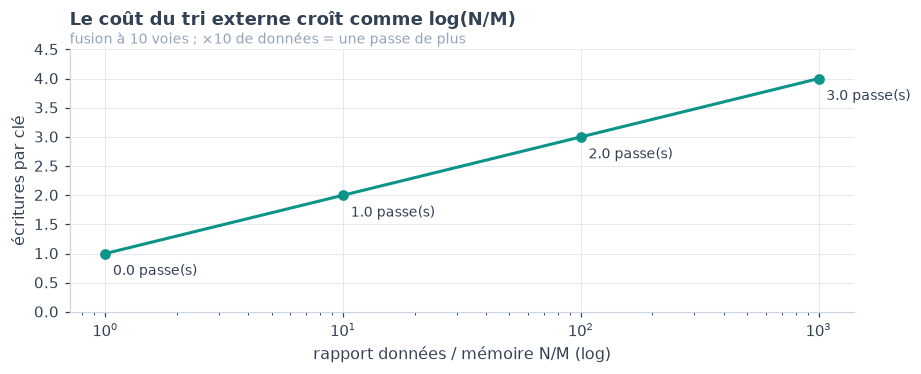

,rapport,segments,passes,formule,ecritures_par_cle
0,1,1,0,0,1.0
1,10,10,1,1,2.0
2,100,100,2,2,3.0
3,1000,1000,3,3,4.0


In [3]:
rng = np.random.default_rng(1)
N = 60_000
data = [f"{a}|{b}" for a, b in zip(rng.integers(0, 10**6, N), rng.integers(0, 10**4, N))]
rows = []
for M in [60_000, 6_000, 600, 60]:
    out, st = B.external_sort(data, max_in_memory=M, fan_in=10)
    assert out == sorted(data)
    rows.append(dict(rapport=N // M, segments=st.n_runs, passes=st.merge_passes, formule=B.merge_passes(st.n_runs, 10),
                     ecritures_par_cle=st.records_written / N))
R = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.5))
ax.semilogx(R.rapport, R.ecritures_par_cle, "o-", color=TEAL)
for _, r in R.iterrows():
    ax.annotate(f"{r.passes} passe(s)", (r.rapport, r.ecritures_par_cle), (5, -14), textcoords="offset points", fontsize=9)
ax.set_xlabel("rapport données / mémoire N/M (log)"); ax.set_ylabel("écritures par clé")
ax.set_ylim(0, 4.5)
ax.set_title("Le coût du tri externe croît comme log(N/M)")
subtitle(ax, "fusion à 10 voies ; ×10 de données = une passe de plus")
plt.tight_layout(); plt.show()
R

Chaque multiplication par 10 du rapport $N/M$ ajoute exactement une passe, comme le
prévoit $\lceil \log_{10}(N/M) \rceil$.

> **À retenir.** Quand l'ensemble de travail dépasse la RAM, le tri externe prend le
> relais avec un coût logarithmique en $N/M$ ; avec une fusion assez large, une seule
> passe suffit souvent et le temps est dominé par la lecture de l'entrée. Toujours
> estimer le nombre de clés **distinctes** avant de choisir.

## Exercice 11.2 : régler la fusion d'un tri externe

**Énoncé.** On trie $D = 1$ To sur un disque dur (débit séquentiel 200 Mo/s, temps
d'accès 8 ms) avec $M = 8$ Go de mémoire. Pendant une fusion à $k$ voies, la mémoire est
partagée en $k+1$ tampons (un par segment lu, un pour la sortie) ; chaque fois qu'un
tampon d'entrée est vide, on fait un accès disque pour le remplir.

1. Combien de segments produit la première phase ? Exprimer le nombre de passes en
   fonction de $k$.
2. Pour une passe, combien d'accès disque faut-il ? En déduire la durée d'une passe en
   fonction de $k$, puis la durée totale.
3. Tracer la durée totale pour $k$ de 2 à 1 000 et trouver le $k$ optimal. Que
   deviendrait l'optimum sur un SSD (accès de 0,1 ms) ?
4. Vérifier le nombre de passes avec `B.external_sort` à échelle réduite.

**Rappels.** Tri externe et fusion à $k$ voies : cours 1, section 4 ; écritures
séquentielles contre aléatoires : chapitre 4.

**Solution.**

*1.* $D/M = 125$ segments, d'où $p(k) = \lceil \log_k 125 \rceil$ passes : 7 pour $k = 2$,
3 pour $k = 5$, 2 pour $k$ de 12 à 124, 1 dès $k = 125$.

*2.* Chaque tampon fait $M/(k+1)$ ; une passe lit et écrit tout $D$, soit $2D/(M/(k+1))$
remplissages ou vidages de tampon, chacun avec un accès. Durée d'une passe :
$T_1(k) = 2D/\text{débit} + 2D(k+1)/M \times t_{\text{accès}}$. Durée totale (phase de
création des segments comprise, une lecture et une écriture séquentielles) :
$T(k) = 2D/\text{débit} + p(k)\,T_1(k)$.

*3.* Le débit seul coûte $2D/\text{débit} = 10\,000$ s par passe ; les accès coûtent
$250 (k+1) \times 8$ ms $= 2(k+1)$ s par passe : négligeables tant que $k$ reste en
dessous de quelques centaines. Le minimum est donc atteint au **plus petit $k$ qui donne
une seule passe**, $k = 125$ : une passe d'environ 10 250 s, plus 10 000 s pour créer les
segments, soit 5,6 h au total (contre 8,4 h avec deux passes). Avec $k = 1\,000$, les
accès ajoutent 2 000 s. Sur SSD, les accès deviennent
80 fois moins chers : la courbe est plate au-delà de $k = 125$, et l'on peut fusionner
très largement sans pénalité.

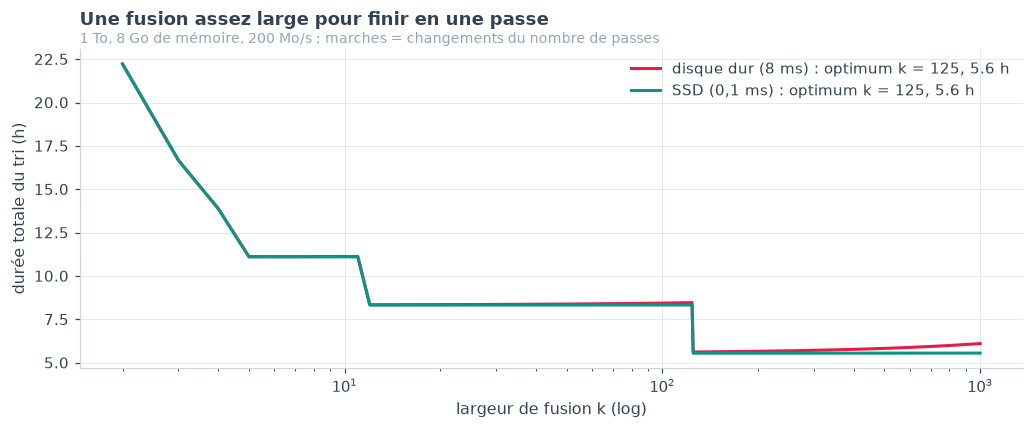

In [4]:
D, M, debit = 1e12, 8e9, 200e6
ks = np.unique(np.concatenate([np.logspace(np.log10(2), 3, 200).astype(int), [124, 125]]))
fig, ax = plt.subplots(figsize=(9.5, 4))
for acces, c, nom in [(8e-3, ROSE, "disque dur (8 ms)"), (1e-4, TEAL, "SSD (0,1 ms)")]:
    T = []
    for k in ks:
        p = B.merge_passes(math.ceil(D / M), int(k))
        T.append(2 * D / debit + p * (2 * D / debit + 2 * D * (k + 1) / M * acces))
    T = np.array(T) / 3600
    kopt = ks[T.argmin()]
    ax.semilogx(ks, T, color=c, label=f"{nom} : optimum k = {kopt}, {T.min():.1f} h")
ax.set_xlabel("largeur de fusion k (log)"); ax.set_ylabel("durée totale du tri (h)")
ax.set_title("Une fusion assez large pour finir en une passe")
subtitle(ax, "1 To, 8 Go de mémoire, 200 Mo/s ; marches = changements du nombre de passes")
ax.legend()
plt.tight_layout(); plt.show()

In [5]:
rows = []
data = [f"{x:08d}" for x in np.random.default_rng(2).permutation(125 * 400)]
for k in [2, 5, 12, 125]:
    out, st = B.external_sort(data, max_in_memory=400, fan_in=k)
    rows.append({"k": k, "segments": st.n_runs, "passes mesurées": st.merge_passes,
                 "passes prévues": B.merge_passes(125, k)})
pd.DataFrame(rows).set_index("k")

,segments,passes mesurées,passes prévues
k,,,
2,125,7,7
5,125,3,3
12,125,2,2
125,125,1,1


Les passes mesurées (125 segments) suivent $\lceil \log_k 125 \rceil$. Sur disque dur, le
temps total ne dépend presque que du nombre de passes, d'où les marches de la courbe.

> **À retenir.** Un tri externe coûte (nombre de passes) × (lecture + écriture de tout).
> La bonne largeur de fusion est la plus petite qui ramène le tri à une ou deux passes ;
> au-delà, des tampons trop petits multiplient les accès, ce qui pénalise surtout les
> disques durs.

## Exercice 11.3 : dimensionner un système de fichiers distribué

**Énoncé.** Un cluster doit stocker 5 Po de données utiles, en fichiers de 200 Mo en
moyenne, avec des blocs de 128 Mo. Les disques font 10 To et coûtent 250 € ; chaque
objet (fichier ou bloc) coûte environ 150 octets de mémoire au service de métadonnées.

1. Combien de fichiers et de blocs ? Quelle mémoire pour les métadonnées ?
2. Une équipe ajoute 500 millions de petits fichiers de 100 Ko (soit 50 To de plus,
   1 % du volume). Que devient la mémoire des métadonnées ?
3. Comparer le nombre de disques et leur coût avec une triple réplication et avec un
   code RS(6, 3).
4. Un disque de 10 To meurt. Quel volume faut-il lire sur le réseau pour reconstruire
   ses données, dans chaque cas ?
5. Avec une probabilité $p = 10^{-3}$ de perdre un fragment avant réparation, comparer
   les probabilités de perdre un bloc.

**Rappels.** Blocs, NameNode, réplication et codes d'effacement : cours 2, sections 2 et
3 (section *Distributed Filesystems*).

**Solution.**

*1.* $5 \cdot 10^{15} / 2 \cdot 10^8 = 25$ millions de fichiers de 2 blocs chacun
($\lceil 200/128 \rceil$), soit 75 millions d'objets et $75 \cdot 10^6 \times 150
\approx 11$ Go de mémoire : un serveur ordinaire.

*2.* 500 millions de fichiers d'un bloc : $10^9$ objets de plus, 150 Go. Les petits
fichiers font 1 % du volume mais **93 %** de la mémoire des métadonnées. C'est le
problème classique des petits fichiers : on les regroupe (archives, formats en conteneur)
avant de les stocker.

*3.* Réplication ×3 : 15 Po bruts, 1 500 disques, 375 000 €. RS(6, 3) : facteur 1,5,
7,5 Po, 750 disques, 187 500 €. Le code d'effacement divise le coût par deux.

*4.* Réplication : chaque bloc perdu se recopie depuis une copie survivante : 10 To lus.
RS(6, 3) : chaque fragment perdu se reconstruit à partir de 6 autres fragments : 60 To
lus sur le réseau, six fois plus (d'où des codes plus élaborés, dits *locally
repairable*, qui réduisent ce trafic).

*5.* $p^3 = 10^{-9}$ pour la réplication ; environ $\binom{9}{4} p^4 \approx 1{,}3
\cdot 10^{-10}$ pour RS(6, 3), qui tolère trois pertes sur neuf.

métadonnées : 11.2 Go, puis 161 Go avec les petits fichiers (93% de la mémoire pour 1 % du volume)


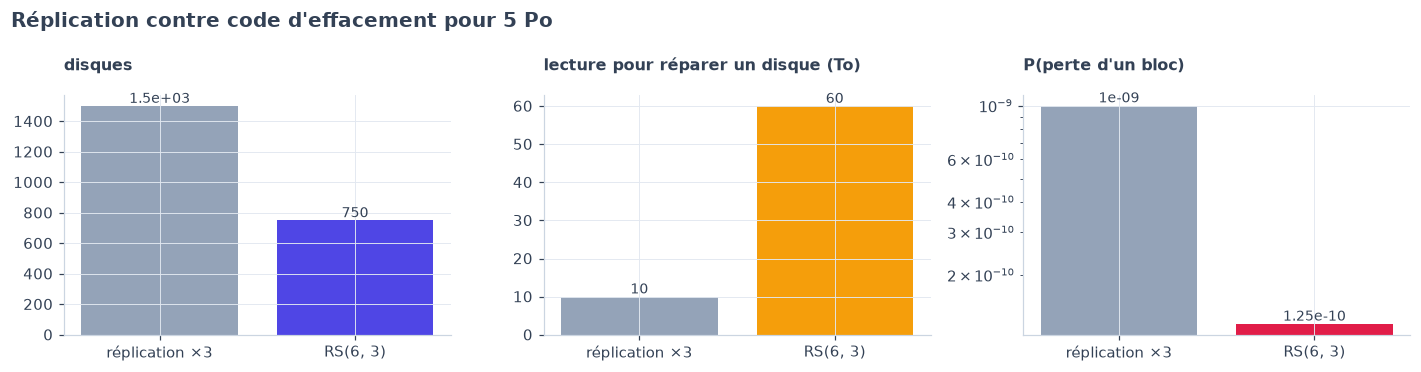

,réplication ×3,"RS(6, 3)"
disques,1.500e+03,7.500e+02
coût (€),3.750e+05,1.875e+05
lecture pour réparer un disque (To),1.000e+01,6.000e+01
P(perte d'un bloc),1.000e-09,1.255e-10


In [6]:
mem_base = B.namenode_memory(5e15, 128e6, 200e6)
mem_petits = 500e6 * 2 * 150
res = pd.DataFrame({
    "réplication ×3": [3 * 5e15 / 10e12, 3 * 5e15 / 10e12 * 250, 10, B.p_loss_replication(1e-3, 3)],
    "RS(6, 3)": [1.5 * 5e15 / 10e12, 1.5 * 5e15 / 10e12 * 250, 60, B.p_loss_erasure(1e-3, 6, 3)],
}, index=["disques", "coût (€)", "lecture pour réparer un disque (To)", "P(perte d'un bloc)"])
print(f"métadonnées : {mem_base / 1e9:.1f} Go, puis {(mem_base + mem_petits) / 1e9:.0f} Go avec les petits fichiers "
      f"({mem_petits / (mem_base + mem_petits):.0%} de la mémoire pour 1 % du volume)")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, ligne, c in zip(axes, ["disques", "lecture pour réparer un disque (To)", "P(perte d'un bloc)"], [INDIGO, AMBER, ROSE]):
    ax.bar(res.columns, res.loc[ligne], color=[GRAY, c])
    ax.set_title(ligne, fontsize=10.5)
    if ligne.startswith("P"):
        ax.set_yscale("log")
    for i, v in enumerate(res.loc[ligne]):
        ax.text(i, v, f"{v:.3g}", ha="center", va="bottom", fontsize=9)
finish(fig, "Réplication contre code d'effacement pour 5 Po")
plt.show()
res

> **À retenir.** Ce sont les **objets** (fichiers et blocs), pas les octets, qui
> remplissent la mémoire des métadonnées : méfiance envers les petits fichiers. Les codes
> d'effacement divisent le stockage par deux à durabilité égale ou meilleure, mais
> multiplient le trafic de réparation.

## Exercice 11.4 : préemption et taille des tâches

**Énoncé.** Un job représente 2 000 heures-cœur de calcul et dispose de 200 cœurs. Ses
tâches tournent en basse priorité et sont préemptées au taux $\lambda = 0{,}1$ par heure
(processus de Poisson) ; une tâche préemptée recommence depuis le début. Chaque
tentative coûte en plus un temps fixe $o$ de démarrage (lancement, lecture de l'entrée).

1. Avec $o = 0$, calculer la durée moyenne d'une tâche de 10 h, 1 h et 6 min, et le
   surcoût relatif. Quelle durée de job peut-on espérer dans chaque cas ?
2. Avec $o = 2$ min, écrire le surcoût relatif $f(T) = \mathbb{E}[D]/T$ en fonction de
   la durée utile $T$ d'une tâche, et trouver le $T$ optimal. Montrer que
   $T^* \approx \sqrt{2o/\lambda}$ quand $\lambda T \ll 1$.
3. Vérifier par simulation (`B.simulate_job`).

**Rappels.** Relance depuis le début, $\mathbb{E}[D] = (e^{\lambda T} - 1)/\lambda$,
granularité des tâches : cours 2, section 5 (section *Handling faults*).

**Solution.**

*1.* $\mathbb{E}[D]/T = (e^{\lambda T} - 1)/(\lambda T)$ : pour $T = 10$ h, $(e - 1)/1
= 1{,}72$ (+72 %) ; pour 1 h, $1{,}052$ (+5 %) ; pour 6 min, $1{,}005$ (+0,5 %). Le job
idéal dure $2\,000/200 = 10$ h ; avec des tâches de 10 h, il n'y a que 200 tâches, une
par cœur, et le job dure jusqu'à la fin de la **plus lente** : bien plus que 17 h en
moyenne, car le maximum de 200 durées aléatoires est loin de leur moyenne. Avec des
tâches de 1 h ou 6 min, le job dure environ 10,5 h ou 10,05 h.

*2.* Avec démarrage : $f(T) = (e^{\lambda(T+o)} - 1)/(\lambda T)$. Pour $\lambda(T+o)
\ll 1$ : $f(T) \approx (T + o)(1 + \lambda (T+o)/2)/T \approx 1 + o/T + \lambda T/2$
(au premier ordre). La dérivée $-o/T^2 + \lambda/2$ s'annule pour $T^* = \sqrt{2o/\lambda}
= \sqrt{2 \times (2/60) / 0{,}1} \approx 0{,}82$ h, soit environ 49 min, pour un surcoût
d'environ $2\sqrt{o\lambda/2} \approx 8$ %. C'est la même forme que la formule de Young
pour les sauvegardes (cours 4).

T =   10 h : E[D]/T = 1.718
T =    1 h : E[D]/T = 1.052
T =  0.1 h : E[D]/T = 1.005


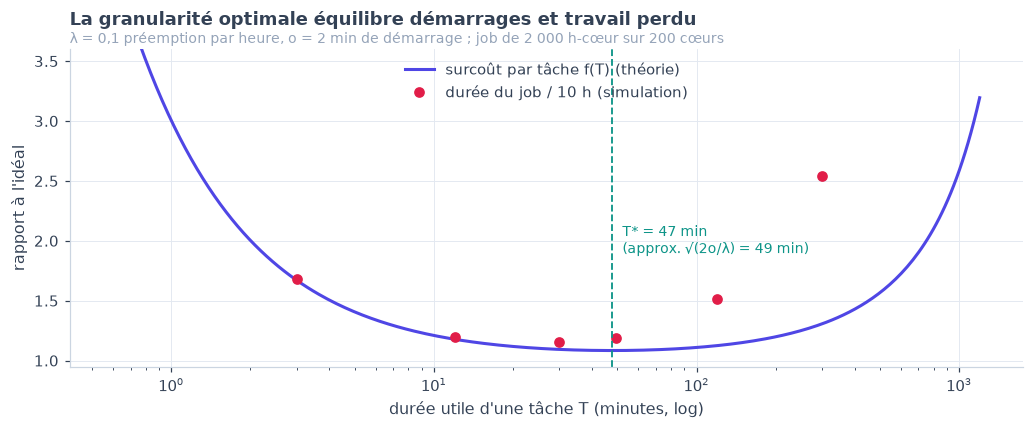

In [7]:
lam, o = 0.1, 2 / 60
for T in [10, 1, 0.1]:
    print(f"T = {T:>4} h : E[D]/T = {B.expected_time_with_restarts(T, lam) / T:.3f}")
Ts = np.logspace(-2, 1.3, 300)
f = (np.expm1(lam * (Ts + o)) / lam) / Ts
T_star = Ts[f.argmin()]
T_approx = math.sqrt(2 * o / lam)
sim_T = [0.05, 0.2, 0.5, 0.82, 2, 5, 10]
sim = [np.mean([B.simulate_job(2000, int(round(2000 / t)), 200, lam, overhead=o, seed=s) for s in range(3)]) / 10
       for t in sim_T]
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.semilogx(Ts * 60, f, color=INDIGO, label="surcoût par tâche f(T) (théorie)")
ax.semilogx(np.array(sim_T) * 60, sim, "o", color=ROSE, label="durée du job / 10 h (simulation)")
ax.axvline(T_star * 60, color=TEAL, ls="--", lw=1.2)
ax.text(T_star * 60 * 1.1, 1.9, f"T* = {T_star * 60:.0f} min\n(approx. √(2o/λ) = {T_approx * 60:.0f} min)", fontsize=9, color=TEAL)
ax.set_ylim(0.95, 3.6)
ax.set_xlabel("durée utile d'une tâche T (minutes, log)"); ax.set_ylabel("rapport à l'idéal")
ax.set_title("La granularité optimale équilibre démarrages et travail perdu")
subtitle(ax, "λ = 0,1 préemption par heure, o = 2 min de démarrage ; job de 2 000 h-cœur sur 200 cœurs")
ax.legend(loc="upper center")
plt.tight_layout(); plt.show()

La simulation suit la théorie pour les tâches courtes ; elle s'en écarte vers le haut
dès que les tâches s'allongent, pour deux raisons. D'abord le découpage en **vagues** :
avec $T = 49$ min, 2 439 tâches sur 200 cœurs font 12,2 vagues, et la dernière, presque
vide, coûte une vague entière. Ensuite l'effet du **maximum** : le job finit avec sa
dernière tâche, et le maximum de quelques centaines de durées aléatoires dépasse
nettement leur moyenne (avec des tâches de 10 h, le job dure plus du triple de l'idéal).
Les tâches longues sont donc doublement pénalisées, et l'optimum réel se décale un peu
vers des tâches plus courtes que $T^*$.

> **À retenir.** Le surcoût d'une tâche vaut environ $1 + o/T + \lambda T/2$ : des tâches
> trop courtes paient le démarrage, des tâches trop longues le travail perdu. L'optimum
> $T^* \approx \sqrt{2o/\lambda}$ ; et l'effet du maximum pénalise encore davantage les
> jobs faits de peu de tâches longues.

## Exercice 11.5 : le combineur, et pourquoi il ne marche pas pour une moyenne

**Énoncé.** Sur le journal d'accès, on veut (a) le nombre de requêtes par adresse IP et
(b) la taille moyenne des réponses par code de statut.

1. Écrire le job (a) avec `B.run_mapreduce`, puis ajouter un **combineur** (fonction
   appliquée par chaque mappeur à sa sortie triée, avant le shuffle). Mesurer le nombre
   d'enregistrements et d'octets shufflés dans les deux cas.
2. Pour (b), un collègue réutilise la fonction de réduction (la moyenne) comme
   combineur. Montrer que le résultat est faux, et expliquer pourquoi.
3. Corriger le combineur. À quelle condition une fonction peut-elle servir de combineur ?

**Rappels.** Mappeur, réducteur, shuffle et compteurs : cours 3, sections 1 et 2 ;
agrégation en deux étapes : cours 3, section 5.

**Solution.**

*1.* Le combineur somme les 1 de chaque IP **dans chaque mappeur** : chaque mappeur
n'envoie plus qu'un couple par IP distincte qu'il a vue, au lieu d'un par ligne. Le gain
dépend de la répétition des clés dans un même morceau d'entrée : forte pour les IP
populaires (loi de Zipf).

*2.* Moyenne de moyennes : si le mappeur 1 a vu les tailles {100, 200, 300} pour le code
200 et le mappeur 2 la seule taille {1 000}, les combineurs envoient 200 et 1 000, et le
réducteur calcule 600, alors que la vraie moyenne vaut 400. La moyenne n'est pas une
opération qu'on peut appliquer par morceaux puis recombiner : on perd le poids de chaque
morceau.

*3.* On transporte (somme, effectif) : le combineur additionne sommes et effectifs, le
réducteur aussi, et ne divise qu'à la fin. Condition générale : le combineur doit
calculer un **agrégat partiel** que le réducteur sait fusionner, ce qui suppose une
opération **associative et commutative** sur ces agrégats (somme, min, max, comptage,
union d'ensembles, couples (somme, effectif)). Le framework peut appliquer le combineur
zéro, une ou plusieurs fois : le résultat ne doit pas en dépendre.

In [8]:
lines = B.generate_access_log(150_000, n_urls=1500, n_ips=5000, seed=8)
shards = [lines[i::6] for i in range(6)]


def m_ip(l):
    yield l.split()[0], 1


def somme_reduce(k, vs):
    yield [k, sum(vs)]


def somme_combine(k, vs):
    yield sum(vs)


sans, st_sans = B.run_mapreduce(shards, m_ip, somme_reduce, n_reducers=4)
avec, st_avec = B.run_mapreduce(shards, m_ip, somme_reduce, n_reducers=4, combiner=somme_combine)
assert sorted(x for o in sans for x in o) == sorted(x for o in avec for x in o)


def m_statut(l):
    f = l.split()
    yield int(f[8]), int(f[9])


def moyenne_reduce(k, vs):
    vs = list(vs)
    yield [k, sum(vs) / len(vs)]


def moyenne_combine_faux(k, vs):                    # réutilise la moyenne comme combineur
    vs = list(vs)
    yield sum(vs) / len(vs)


def m_statut_paire(l):
    f = l.split()
    yield int(f[8]), [int(f[9]), 1]


def paire_combine(k, vs):
    s = n = 0
    for a, b in vs:
        s += a; n += b
    yield [s, n]


def paire_reduce(k, vs):
    s = n = 0
    for a, b in vs:
        s += a; n += b
    yield [k, s / n]


# des morceaux d'entrée de tailles très différentes, comme des blocs de fichiers inégaux
inegaux = [lines[:2000], lines[2000:2100], lines[2100:]]
vrai = dict(x for o in B.run_mapreduce(inegaux, m_statut, moyenne_reduce, n_reducers=2)[0] for x in o)
faux = dict(x for o in B.run_mapreduce(inegaux, m_statut, moyenne_reduce, n_reducers=2, combiner=moyenne_combine_faux)[0] for x in o)
juste = dict(x for o in B.run_mapreduce(inegaux, m_statut_paire, paire_reduce, n_reducers=2, combiner=paire_combine)[0] for x in o)
pd.DataFrame({"sans combineur (référence)": vrai, "moyenne comme combineur": faux, "combineur (somme, effectif)": juste}).round(1)

,sans combineur (référence),moyenne comme combineur,"combineur (somme, effectif)"
404,20038.1,18524.3,20038.1
200,20125.2,20207.6,20125.2
304,0.0,0.0,0.0


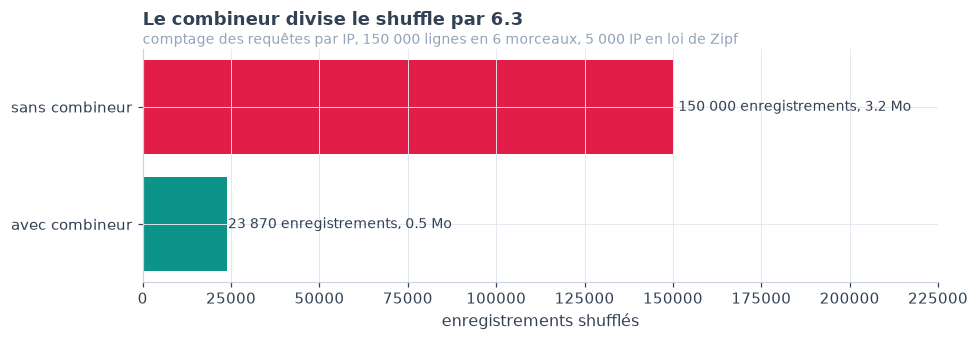

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.2))
vals = [st_sans.shuffle_records, st_avec.shuffle_records]
octs = [st_sans.shuffle_bytes / 1e6, st_avec.shuffle_bytes / 1e6]
ax.barh(["sans combineur", "avec combineur"], vals, color=[ROSE, TEAL])
for i, (v, b_) in enumerate(zip(vals, octs)):
    ax.text(v * 1.01, i, f"{fmt(v)} enregistrements, {b_:.1f} Mo", va="center", fontsize=9)
ax.set_xlim(0, max(vals) * 1.5); ax.invert_yaxis()
ax.set_xlabel("enregistrements shufflés")
ax.set_title(f"Le combineur divise le shuffle par {vals[0] / vals[1]:.1f}")
subtitle(ax, "comptage des requêtes par IP, 150 000 lignes en 6 morceaux, 5 000 IP en loi de Zipf")
plt.tight_layout(); plt.show()

Le combineur divise le volume du shuffle sans changer le résultat du comptage ; la
moyenne utilisée comme combineur donne des valeurs fausses (environ 80 octets d'écart
pour le code 200, 1 500 pour le code 404, plus rare et donc plus sensible au poids des
morceaux), et la version (somme, effectif) retrouve exactement la référence.

> **À retenir.** Un combineur pré-agrège la sortie de chaque mappeur et réduit le
> shuffle ; il doit produire des agrégats **partiels** fusionnables par une opération
> associative et commutative. Une moyenne se transporte en (somme, effectif).